**Libraries Installation**



In [ ]:
!pip -q install kagglehub mediapipe opencv-python-headless scikit-learn matplotlib seaborn joblib
!wget -q -O hand_landmarker.task https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task


**Imports**

In [ ]:
import os, shutil, glob, zipfile
from pathlib import Path
import cv2
import mediapipe as mp
import numpy as np

from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from IPython.display import Javascript
from google.colab.output import eval_js
from base64 import b64decode
from tqdm import tqdm
import pandas as pd
import numpy as np
import joblib
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix


**Dataset Preparation**

In [ ]:
DATA_ROOT = "/content/data"
os.makedirs(DATA_ROOT, exist_ok=True)

try:
    import kagglehub
    dataset_path = kagglehub.dataset_download("grassknoted/asl-alphabet")
    print("Dataset downloaded to:", dataset_path)

except Exception:
    print("Automatic Kaggle download failed.")
    print("Upload the dataset ZIP manually.")

    uploaded = files.upload()

    for fname in uploaded:
        if fname.endswith(".zip"):
            with zipfile.ZipFile(fname, "r") as zip_ref:
                zip_ref.extractall(DATA_ROOT)

            dataset_path = DATA_ROOT
            print("Dataset extracted to:", dataset_path)


valid_classes = [c for c in "ABCDEFGHIJKLMNOPQRSTUVWXYZ"]


def find_class_dir(base):
    for root, dirs, files in os.walk(base):
        upper_dirs = sorted([d.upper() for d in dirs])
        count = sum(c in upper_dirs for c in valid_classes)

        if count >= 26:
            return root

    return None


CLASS_DIR = find_class_dir(dataset_path)

print("Detected class directory:", CLASS_DIR)

classes = sorted([
    d for d in os.listdir(CLASS_DIR)
    if d.upper() in valid_classes
])

print("Classes:", classes)
print("Number of classes:", len(classes))



Using Colab cache for faster access to the 'asl-alphabet' dataset.
Dataset downloaded to: /kaggle/input/asl-alphabet
Detected class directory: /kaggle/input/asl-alphabet/asl_alphabet_train/asl_alphabet_train
Classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']
Number of classes: 26


**MediaPipe Step for training feature extraction**

In [ ]:
BaseOptions = mp.tasks.BaseOptions
HandLandmarker = vision.HandLandmarker
HandLandmarkerOptions = vision.HandLandmarkerOptions
VisionRunningMode = vision.RunningMode

options = HandLandmarkerOptions(
    base_options=BaseOptions(model_asset_path="hand_landmarker.task"),
    running_mode=VisionRunningMode.IMAGE,
    num_hands=1
)

detector = HandLandmarker.create_from_options(options) #Creates MediaPipe detector

print("MediaPipe detector ready.")


def extract_landmarks_from_image(img_bgr):
    rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB) #Because MediaPipe expectes RGB
    mp_image = mp.Image( #Converts the image into MediaPipe
        image_format=mp.ImageFormat.SRGB,
        data=rgb
    )

    result = detector.detect(mp_image) #Detects hand landmarks

    if not result.hand_landmarks:
        return None

    hand_landmarks = result.hand_landmarks[0]

    features = []

    for lm in hand_landmarks:
        features.extend([lm.x, lm.y, lm.z]) #z is the depth relative to the camera

    return features


X = []
y = []
failed = 0

MAX_IMAGES_PER_CLASS = 400 #To reduce training time and keep dataset balanced across classes

#Data Preprocessing

for label in classes:
    folder = os.path.join(CLASS_DIR, label)
    image_paths = glob.glob(folder + "/*")

    print(f"\nProcessing class {label}: {len(image_paths)} images")

    count = 0

    for img_path in tqdm(image_paths[:MAX_IMAGES_PER_CLASS]):
        img = cv2.imread(img_path)

        if img is None:
            failed += 1
            continue

        features = extract_landmarks_from_image(img)

        if features is None:
            failed += 1
            continue

        X.append(features)
        y.append(label.upper())
        count += 1

    print(f"Extracted {count} valid samples for class {label}")


X = np.array(X, dtype=np.float32)
y = np.array(y)

print("\nFinal feature matrix shape:", X.shape)
print("Final label vector shape:", y.shape)
print("Failed images:", failed)



MediaPipe detector ready.

Processing class A: 3000 images


100%|██████████| 400/400 [00:17<00:00, 23.51it/s]


Extracted 293 valid samples for class A

Processing class B: 3000 images


100%|██████████| 400/400 [00:18<00:00, 21.13it/s]


Extracted 288 valid samples for class B

Processing class C: 3000 images


...

Extracted 299 valid samples for class X

Processing class Y: 3000 images


100%|██████████| 400/400 [00:18<00:00, 21.66it/s]


Extracted 342 valid samples for class Y

Processing class Z: 3000 images


100%|██████████| 400/400 [00:17<00:00, 22.86it/s]

Extracted 309 valid samples for class Z

Final feature matrix shape: (8066, 63)
Final label vector shape: (8066,)
Failed images: 2334


**SVM Training**

Linear SVM Accuracy: 97.27 %

Classification Report:
              precision    recall  f1-score   support

           A       0.97      1.00      0.98        59
           B       0.98      1.00      0.99        58
           C       1.00      1.00      1.00        52
           D       0.98      0.97      0.98        65
           E       0.97      0.98      0.98        65
           F       0.99      0.97      0.98        77
           G       0.97      0.98      0.98        65
           H       0.98      0.98      0.98        65
           I       1.00      0.93      0.97        61
           J       1.00      0.97      0.99        69
           K       0.97      0.99      0.98        72
           L       1.00      1.00      1.00        66
           M       0.89      0.81      0.85        42
           N       0.91      0.85      0.88        34
           O       0.97      1.00      0.98        60
           P       0.96      0.96      0.96        57
           Q       0.96     

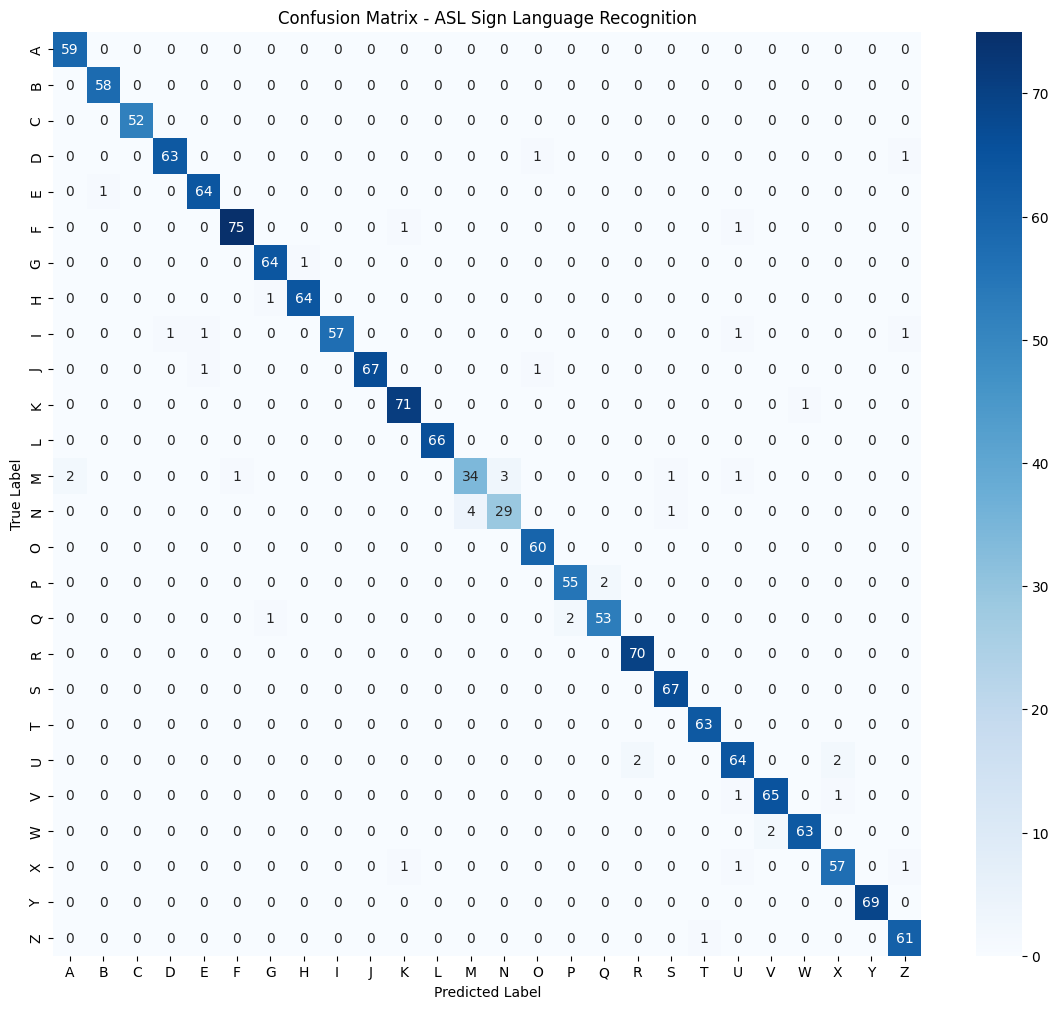

Saved confusion matrix to /content/confusion_matrix.png


In [ ]:
# Encode labels
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y) #this converts A to 0, B to 1, etc

# Scale landmark features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X) #Normalizes features

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded #Ensures all classes are balanced
)

# Linear SVM model
linear_svm = LinearSVC(. #“Because linear SVM is computationally simpler and more FPGA-friendly than nonlinear kernels.”
    C=1.0, #Controls regularization
    max_iter=20000 #To ensure convergance durin optimization
)

linear_svm.fit(X_train, y_train) #learns weights and decision boundaries

# Prediction
y_pred = linear_svm.predict(X_test) #Predicts test class

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Linear SVM Accuracy:", round(accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=encoder.classes_
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(14, 12))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - ASL Sign Language Recognition")
plt.savefig("/content/confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved confusion matrix to /content/confusion_matrix.png")


**SVM WEIGHTS, BIAS, AND FPGA QUANTIZATION**

In [ ]:
#Extracting weights and biases
W = linear_svm.coef_
B = linear_svm.intercept_

print("Weights shape:", W.shape)
print("Bias shape:", B.shape)

SCALE = 256

W_q = np.round(W * SCALE).astype(np.int16) #converts floating point to integer
B_q = np.round(B * SCALE * SCALE).astype(np.int32)

print("Quantized W range:", W_q.min(), W_q.max())
print("Quantized B range:", B_q.min(), B_q.max())


# Optional: Save model components
joblib.dump(linear_svm, "/content/linear_svm_model.pkl")
joblib.dump(scaler, "/content/scaler.pkl")
joblib.dump(encoder, "/content/label_encoder.pkl")

print("Saved SVM model, scaler, and label encoder.")

NameError: name 'linear_svm' is not defined

**Inference**

In [ ]:

def take_frame():
    js = Javascript('''
        async function takePhoto() {
            const div = document.createElement('div');
            const video = document.createElement('video');
            video.style.display = 'block';
            const stream = await navigator.mediaDevices.getUserMedia({video: true});
            document.body.appendChild(div);
            div.appendChild(video);
            video.srcObject = stream;
            await video.play();

            await new Promise(resolve => setTimeout(resolve, 1000));

            const canvas = document.createElement('canvas');
            canvas.width = video.videoWidth;
            canvas.height = video.videoHeight;
            canvas.getContext('2d').drawImage(video, 0, 0);

            stream.getTracks().forEach(track => track.stop());
            div.remove();

            return canvas.toDataURL('image/jpeg');
        }
    ''')
    display(js)
    data = eval_js('takePhoto()')
    binary = b64decode(data.split(',')[1])
    return binary

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Capture webcam image
img_bytes = take_frame()

np_arr = np.frombuffer(img_bytes, np.uint8)
frame = cv2.imdecode(np_arr, cv2.IMREAD_COLOR)

# Extract features
features = extract_landmarks_from_image(frame)

if features is None:
    print("No hand detected. Run again.")

else:

    # ================================
    # RAW FEATURE VECTOR (NON-QUANTIZED)
    # ================================

    features_np = np.array(features).reshape(1, -1)

    print("====================================")
    print("RAW FEATURE VECTOR")
    print("====================================")
    print(features_np[0])
    print("Number of raw features:", len(features_np[0]))

    # ================================
    # FEATURE NORMALIZATION
    # ================================

    # Apply same scaler used during training
    features_scaled = scaler.transform(features_np)

    print("\n====================================")
    print("NORMALIZED FEATURE VECTOR")
    print("====================================")
    print(features_scaled[0])
    print("Number of normalized features:", len(features_scaled[0]))

    # ================================
    # PYTHON SVM PREDICTION
    # ================================

    pred_num = linear_svm.predict(features_scaled)[0]
    pred_label = encoder.inverse_transform([pred_num])[0] #Converts 24 to Y

    print("\n====================================")
    print("PYTHON SVM PREDICTION")
    print("====================================")
    print("Predicted Class Index:", pred_num)
    print("Predicted Letter:", pred_label)

    # ================================
    # DISPLAY IMAGE
    # ================================

    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(6,6))
    plt.imshow(rgb)
    plt.axis("off")
    plt.title(f"Predicted Letter: {pred_label}")
    plt.show()

    # ================================
    # QUANTIZATION FOR FPGA
    # ================================

    SCALE = 256

    features_q = np.round(features_scaled[0] * SCALE).astype(int)

    print("\n====================================")
    print("QUANTIZED FEATURE VECTOR")
    print("====================================")
    print(features_q)
    print("Number of quantized features:", len(features_q))

    # ================================
    # GENERATE VHDL TESTBENCH
    # ================================

    tb_code = """
library ieee;
use ieee.std_logic_1164.all;
use ieee.numeric_std.all;
use work.svm_pkg.all;

entity tb_svm_top is
end entity;

architecture sim of tb_svm_top is

    signal clk             : std_logic := '0';
    signal rst             : std_logic := '1';
    signal start           : std_logic := '0';
    signal x               : feature_vec_t;
    signal predicted_class : unsigned(4 downto 0);
    signal done            : std_logic;

begin

    uut : entity work.svm_top
        port map (
            clk             => clk,
            rst             => rst,
            start           => start,
            x               => x,
            predicted_class => predicted_class,
            done            => done
        );

    clk <= not clk after 5 ns;

    process
    begin
"""

    for i, value in enumerate(features_q):
        tb_code += f"        x({i}) <= to_signed({int(value)}, DATA_W);\n"

    tb_code += """

        wait for 30 ns;
        rst <= '0';

        wait for 20 ns;
        start <= '1';

        wait for 10 ns;
        start <= '0';

        wait until done = '1';

        report "Predicted class index = " & integer'image(to_integer(predicted_class));

        wait for 100 ns;
        assert false report "Simulation finished." severity failure;
    end process;

end architecture;
"""

    with open("/content/tb_svm_top.vhd", "w") as f:
        f.write(tb_code)

    print("\n====================================")
    print("GENERATED FILES")
    print("====================================")
    print("Generated: /content/tb_svm_top.vhd")

    # Download automatically
    files.download("/content/tb_svm_top.vhd")

RAW FEATURE VECTOR
[ 7.19079971e-01  7.90271401e-01 -3.88536620e-07  7.68071353e-01
  7.32459307e-01 -2.93335528e-03  8.18316698e-01  6.74354315e-01
 -1.11651774e-02  8.61634552e-01  6.27987802e-01 -1.88018437e-02
  8.95141602e-01  5.94638884e-01 -2.68266946e-02  7.71334052e-01
  5.93483925e-01 -2.90539600e-02  7.11529434e-01  5.47962129e-01
 -3.06106117e-02  7.02937007e-01  5.83210170e-01 -2.78078262e-02
  7.13113189e-01  6.13986135e-01 -2.53174584e-02  7.33882785e-01
  6.05093479e-01 -3.46903801e-02  6.78128958e-01  5.65262616e-01
 -3.33437324e-02  6.76123798e-01  5.99312425e-01 -3.21062542e-02
  6.87953949e-01  6.28200114e-01 -3.61839309e-02  6.95265651e-01
  6.25319481e-01 -3.75266299e-02  6.51164234e-01  5.79495549e-01
 -3.84768546e-02  6.48390830e-01  6.12058878e-01 -3.43140401e-02
  6.59559429e-01  6.42902792e-01 -3.52268741e-02  6.56907856e-01
  6.48159742e-01 -3.97695750e-02  6.35776877e-01  5.74705839e-01
 -3.96499746e-02  6.23872876e-01  5.31010926e-01 -3.35191302e-02
  6.16


QUANTIZED FEATURE VECTOR
[ 264  110 -261  250  100  269  277  138  230  356  164  226  408  152
  213  294  197    6  194  253  116  169  305  189  169  313  230  329
  217  -16  245  269  150  220  247  227  214  224  242  339  215    4
  281  226  203  233  180  264  213  155  246  332  193   45  306  148
  189  254   38  226  215  -41  216]
Number of quantized features: 63

GENERATED FILES
Generated: /content/tb_svm_top.vhd
